# Homework 4 Lab: Loan Repayment Prediction with a Decision Tree

**Problem:** Use a Decision Tree Classifier to predict whether a loan is repaid, based on the provided loan dataset.

The dataset includes `initial_payment`, `last_payment`, `credit_score`, `house_number`, `sum`, and the target column `result`. The target labels are normalized to `yes` and `no` below. The supplied CSV contains 1,004 records.

**Target variable:** `result` (`yes` = loan repaid; `no` = not repaid).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    RocCurveDisplay,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:.3f}")

### Step 1 - Load the dataset

In [2]:
# Keep Loans_Dataset.csv in the same folder as this notebook.
data = pd.read_csv("Loans_Dataset.csv")

print("Dataset loaded successfully.")
print("Dataset shape (rows, columns):", data.shape)
display(data.head())

Dataset loaded successfully.
Dataset shape (rows, columns): (1004, 6)


,initial_payment,last_payment,credit_score,house_number,sum,result
0,201,10018,250,3046,13515,yes
1,205,10016,395,3044,13660,yes
2,257,10129,109,3251,13746,yes
3,246,10064,324,3137,13771,yes
4,117,10115,496,3094,13822,yes


### Step 2 - Explore the dataset

Review column types, sample records, descriptive statistics, missing values, duplicate rows, and the target distribution before training.

In [3]:
print("Column names:", data.columns.tolist())
data.info()

display(data.head(10))
display(data.describe(include="all"))

print("Missing values by column:")
display(data.isna().sum())
print("Duplicate rows:", data.duplicated().sum())

print("Raw target counts:")
display(data["result"].value_counts(dropna=False))

Column names: ['initial_payment', 'last_payment', 'credit_score', 'house_number', 'sum', 'result']
<class 'pandas.DataFrame'>
RangeIndex: 1004 entries, 0 to 1003
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   initial_payment  1004 non-null   int64
 1   last_payment     1004 non-null   int64
 2   credit_score     1004 non-null   int64
 3   house_number     1004 non-null   int64
 4   sum              1004 non-null   int64
 5   result           1004 non-null   str  
dtypes: int64(5), str(1)
memory usage: 49.6 KB


,initial_payment,last_payment,credit_score,house_number,sum,result
0,201,10018,250,3046,13515,yes
1,205,10016,395,3044,13660,yes
2,257,10129,109,3251,13746,yes
3,246,10064,324,3137,13771,yes
4,117,10115,496,3094,13822,yes
5,406,10187,166,3068,13827,yes
6,461,10252,172,3062,13947,yes
7,158,10192,144,3469,13963,yes
8,136,10376,230,3223,13965,yes
9,194,10092,626,3083,13995,yes


,initial_payment,last_payment,credit_score,house_number,sum,result
count,1004.000,1004.000,1004.000,1004.000,1004.000,1004
unique,NaN,NaN,NaN,NaN,NaN,2
top,NaN,NaN,NaN,NaN,NaN,No
freq,NaN,NaN,NaN,NaN,NaN,521
mean,294.662,12473.010,528.902,4041.283,17744.013,NaN
std,115.844,1442.134,259.682,618.431,9594.660,NaN
min,100.000,10005.000,100.000,3003.000,13515.000,NaN
25%,195.750,11213.500,302.750,3546.500,16081.250,NaN
50%,290.000,12467.000,518.000,4046.000,17383.000,NaN
75%,398.000,13690.000,755.000,4508.750,18608.250,NaN


Missing values by column:


initial_payment    0
last_payment       0
credit_score       0
house_number       0
sum                0
result             0
dtype: int64

Duplicate rows: 0
Raw target counts:


result
No     521
yes    483
Name: count, dtype: int64

### Step 3 - Visualize the target and feature distributions

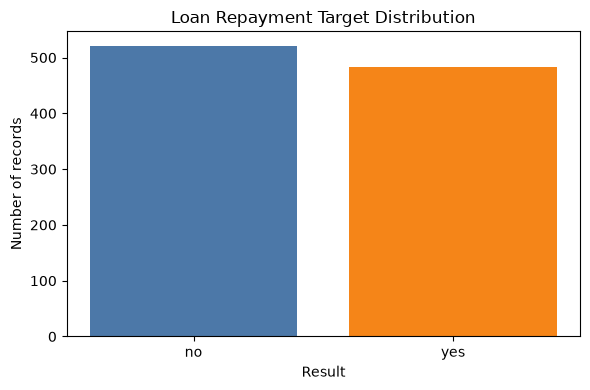

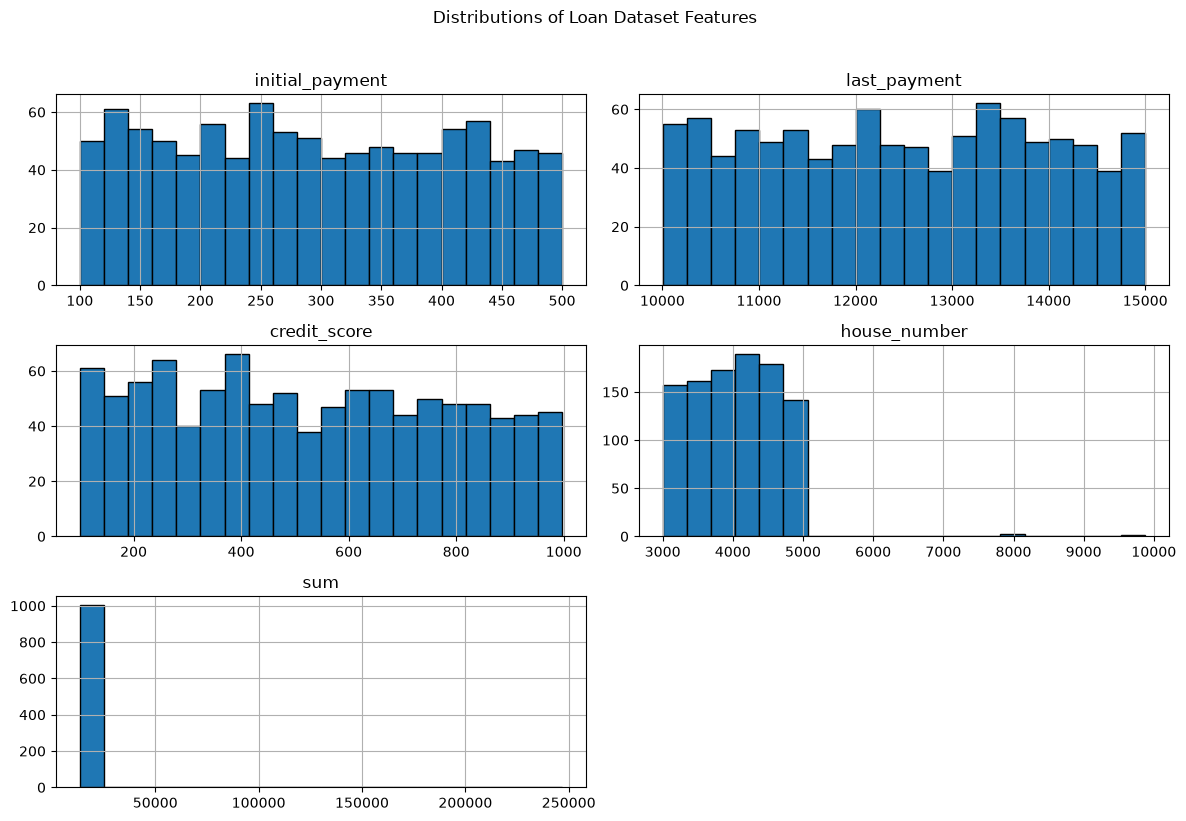

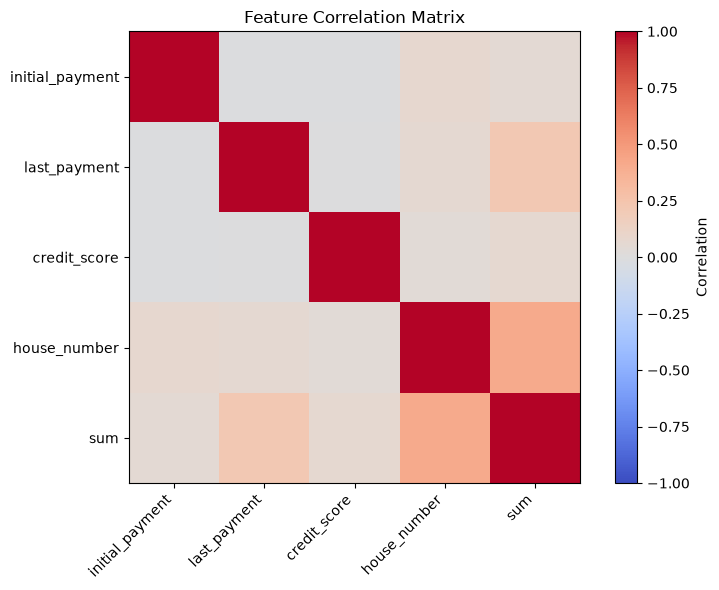

In [4]:
# Target balance: inspect the number of examples in each repayment class.
plt.figure(figsize=(6, 4))
target_counts = data["result"].astype("string").str.strip().str.lower().value_counts()
plt.bar(target_counts.index, target_counts.values, color=["#4C78A8", "#F58518"])
plt.title("Loan Repayment Target Distribution")
plt.xlabel("Result")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

# Feature histograms show the range and shape of each numeric variable.
features_for_plot = data.drop(columns=["result"]).select_dtypes(include="number")
features_for_plot.hist(figsize=(12, 8), bins=20, edgecolor="black")
plt.suptitle("Distributions of Loan Dataset Features", y=1.02)
plt.tight_layout()
plt.show()

# Correlation plot for numeric features; correlation is descriptive, not causal.
correlations = features_for_plot.corr()
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(correlations, cmap="coolwarm", vmin=-1, vmax=1)
fig.colorbar(image, ax=ax, label="Correlation")
ax.set_xticks(range(len(correlations.columns)), correlations.columns, rotation=45, ha="right")
ax.set_yticks(range(len(correlations.index)), correlations.index)
ax.set_title("Feature Correlation Matrix")
fig.tight_layout()
plt.show()

### Step 4 - Clean the data and identify the target

`result` is the target column; the other five columns are the input features. Normalize capitalization and whitespace in the target labels. Convert feature values to numeric values so any invalid entries become missing and can be imputed later.

A decision tree does **not** require feature normalization: it learns split thresholds and is not sensitive to units in the same way as distance-based models. The median imputer is placed in a pipeline so its values are learned only from the training set.

In [5]:
# Normalize label spelling/capitalization, then remove rows without a target label.
data["result"] = data["result"].astype("string").str.strip().str.lower()
data = data.dropna(subset=["result"]).copy()

# Convert all predictors to numeric; unexpected values become NaN and are imputed.
X = data.drop(columns=["result"]).apply(pd.to_numeric, errors="coerce")
y = data["result"]

print("Target classes:", sorted(y.unique().tolist()))
print("Feature columns:", X.columns.tolist())
print("Missing feature values to impute:")
display(X.isna().sum())
print("Cleaned target counts:")
display(y.value_counts())

if y.nunique() != 2:
    raise ValueError("This notebook expects exactly two target classes.")

Target classes: ['no', 'yes']
Feature columns: ['initial_payment', 'last_payment', 'credit_score', 'house_number', 'sum']
Missing feature values to impute:


initial_payment    0
last_payment       0
credit_score       0
house_number       0
sum                0
dtype: int64

Cleaned target counts:


result
no     521
yes    483
Name: count, dtype: int64[pyarrow]

### Step 5 - Split into training and testing sets (80:20)

In [6]:
# Stratification preserves the class proportions in both subsets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)
print("Training class proportions:")
display(y_train.value_counts(normalize=True).sort_index())
print("Testing class proportions:")
display(y_test.value_counts(normalize=True).sort_index())

Training features: (803, 5)
Testing features: (201, 5)
Training labels: (803,)
Testing labels: (201,)
Training class proportions:


result
no    0.519
yes   0.481
Name: proportion, dtype: double[pyarrow]

Testing class proportions:


result
no    0.517
yes   0.483
Name: proportion, dtype: double[pyarrow]

### Step 6 - Build and train the Decision Tree Classifier

A maximum depth and minimum leaf size are set to limit unnecessary tree growth. The pipeline first imputes missing feature values with the training-set median, then fits the classifier.

In [7]:
model = make_pipeline(
    SimpleImputer(strategy="median"),
    DecisionTreeClassifier(
        criterion="gini",
        max_depth=4,
        min_samples_leaf=5,
        random_state=42,
    ),
)

model.fit(X_train, y_train)
print("Decision Tree training complete.")
print(model)

Decision Tree training complete.
Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('decisiontreeclassifier',
                 DecisionTreeClassifier(max_depth=4, min_samples_leaf=5,
                                        random_state=42))])


### Step 7 - Generate predictions

In [8]:
y_pred = model.predict(X_test)

predictions = pd.DataFrame({
    "Actual result": y_test,
    "Predicted result": y_pred,
}, index=y_test.index)

display(predictions.head(15))

,Actual result,Predicted result
176,yes,yes
630,no,no
252,yes,yes
412,yes,yes
409,yes,yes
267,yes,yes
942,no,no
99,yes,yes
263,yes,yes
35,yes,yes


### Step 8 - Evaluate model performance

Accuracy is reported with precision, recall, F1-score, and ROC-AUC so evaluation is not limited to one metric. The positive class for these metrics is `yes`.

Test accuracy:  1.000 (100.0%)
Test precision (yes): 1.000
Test recall (yes):    1.000
Test F1-score (yes):  1.000

Classification report:
              precision    recall  f1-score   support

          no       1.00      1.00      1.00       104
         yes       1.00      1.00      1.00        97

    accuracy                           1.00       201
   macro avg       1.00      1.00      1.00       201
weighted avg       1.00      1.00      1.00       201

ROC-AUC: 1.000


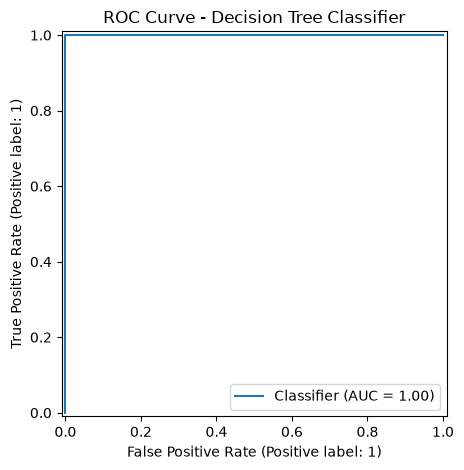

In [9]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label="yes", zero_division=0)
recall = recall_score(y_test, y_pred, pos_label="yes", zero_division=0)
f1 = f1_score(y_test, y_pred, pos_label="yes", zero_division=0)

print(f"Test accuracy:  {accuracy:.3f} ({accuracy * 100:.1f}%)")
print(f"Test precision (yes): {precision:.3f}")
print(f"Test recall (yes):    {recall:.3f}")
print(f"Test F1-score (yes):  {f1:.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, labels=["no", "yes"], zero_division=0))

# Compute ROC-AUC using predicted probability for the positive (yes) class.
classes = model.named_steps["decisiontreeclassifier"].classes_
yes_index = list(classes).index("yes")
y_test_binary = y_test.eq("yes").astype(int)
y_probability = model.predict_proba(X_test)[:, yes_index]
roc_auc = roc_auc_score(y_test_binary, y_probability)
print(f"ROC-AUC: {roc_auc:.3f}")

RocCurveDisplay.from_predictions(y_test_binary, y_probability)
plt.title("ROC Curve - Decision Tree Classifier")
plt.tight_layout()
plt.show()

### Step 9 - Display the confusion matrix

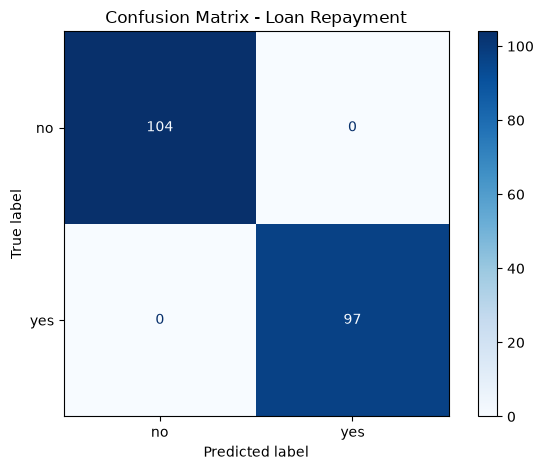

Confusion matrix (rows = actual, columns = predicted):
[[104   0]
 [  0  97]]


In [10]:
labels = ["no", "yes"]
cm = confusion_matrix(y_test, y_pred, labels=labels)

confusion_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
confusion_display.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Loan Repayment")
plt.tight_layout()
plt.show()

print("Confusion matrix (rows = actual, columns = predicted):")
print(cm)

### Step 10 - Inspect the tree and feature importance

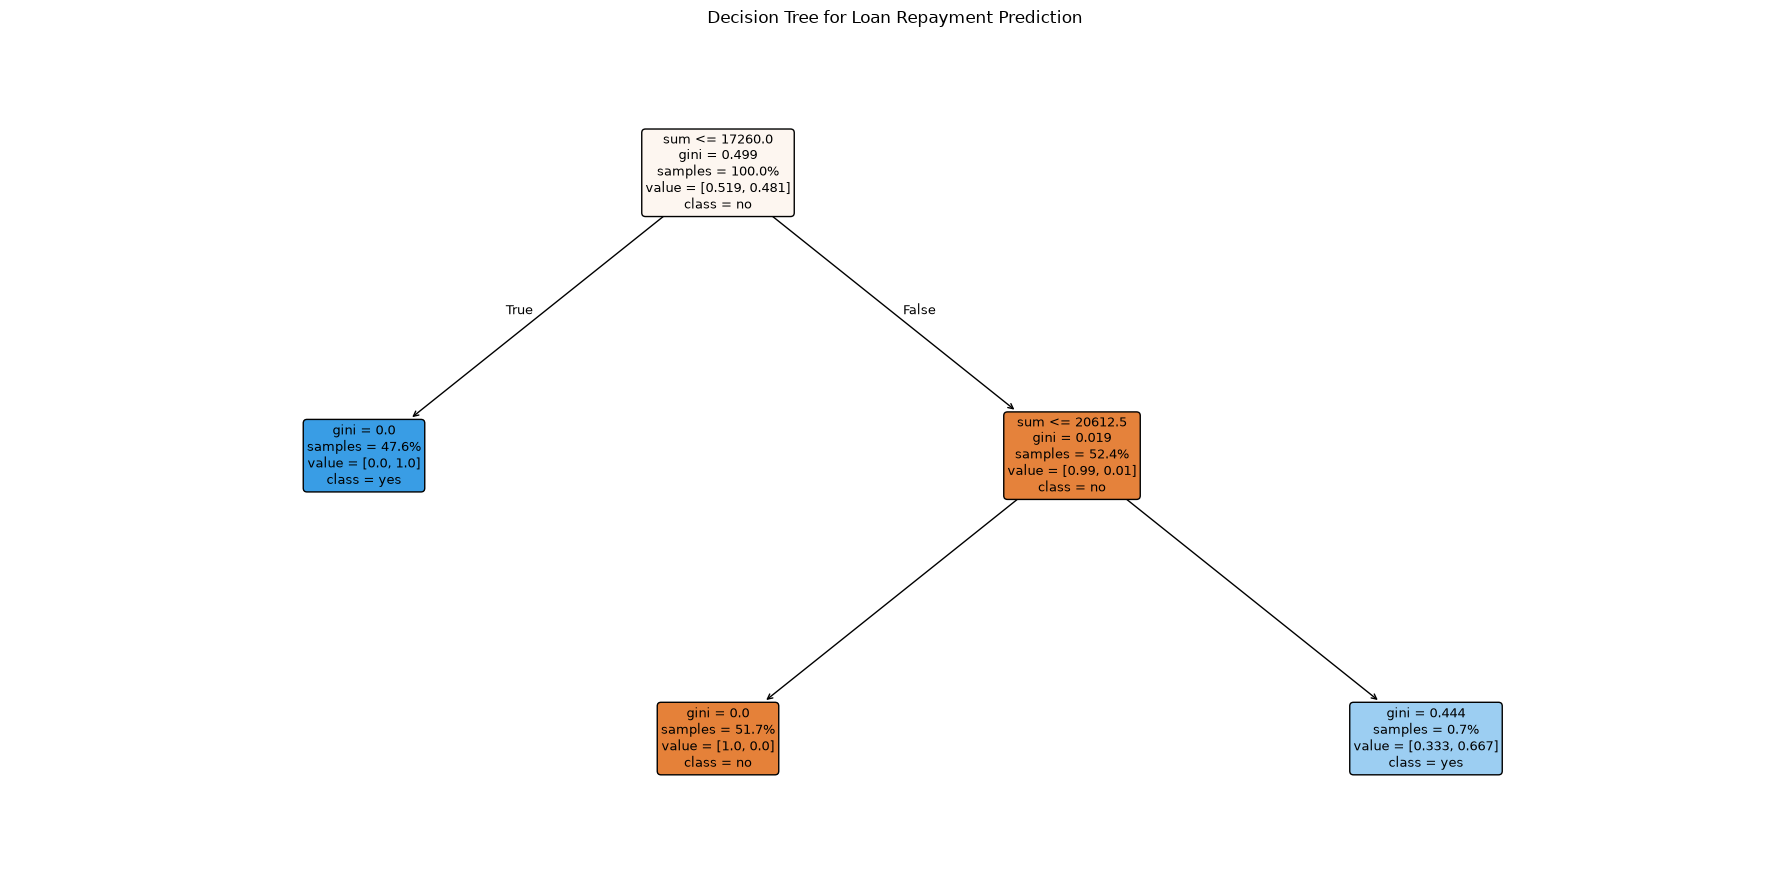

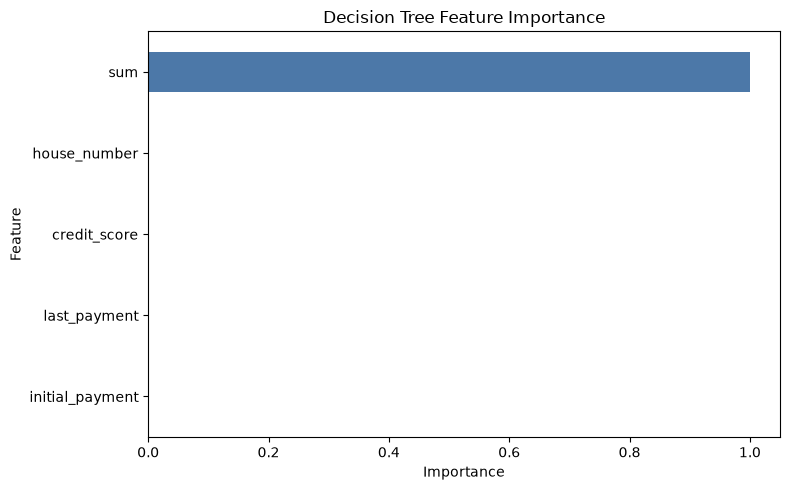

,importance
sum,1.000
initial_payment,0.000
last_payment,0.000
credit_score,0.000
house_number,0.000


In [11]:
tree_model = model.named_steps["decisiontreeclassifier"]

plt.figure(figsize=(18, 9))
plot_tree(
    tree_model,
    feature_names=X.columns,
    class_names=tree_model.classes_,
    filled=True,
    rounded=True,
    proportion=True,
    fontsize=9,
)
plt.title("Decision Tree for Loan Repayment Prediction")
plt.tight_layout()
plt.show()

importance = pd.Series(tree_model.feature_importances_, index=X.columns).sort_values()
plt.figure(figsize=(8, 5))
importance.plot(kind="barh", color="#4C78A8")
plt.title("Decision Tree Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()
display(importance.sort_values(ascending=False).rename("importance").to_frame())

### Conclusion

The model's evaluation above describes performance on one stratified 20% holdout from this dataset. A high score is not evidence that the model will generalize to real lending decisions: the dataset is small and may contain synthetic or dataset-specific patterns. This exercise is for learning classification, not for making real credit or loan decisions.